# Lab 10.2: Prototypes, Criticisms and Neighbors

Chapter 10, *Explaining with Examples and Training Data*. Run the cells from top to bottom; no code needs to be written. Each **Checkpoint** tells you what you should see. Data: the handwritten digits set bundled with scikit-learn (1,797 images of 8 x 8 pixels), so nothing is downloaded.

In [1]:
import numpy as np, warnings
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
warnings.filterwarnings("ignore")
X, y = load_digits(return_X_y=True)
X = X / 16.0                                   # pixel values from 0 to 1
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print("training images:", len(Xtr), " test images:", len(Xte))

training images: 1257  test images: 540


**Checkpoint 1:** 1,257 training images and 540 test images.

## Part A. Prototypes and criticisms with MMD-critic

MMD-critic (Kim, Khanna and Koyejo, 2016) picks prototypes greedily so that the prototypes, seen through a similarity kernel, look as much like the whole class as possible (low maximum mean discrepancy, MMD). Criticisms are the points where the *witness function* is highest: where the data have more mass than the prototypes account for. The paper adds a diversity term for criticisms; this lab simply takes the top witness values.

digit 1: 127 images, prototypes [103, 89, 51], criticisms [23, 32, 49]


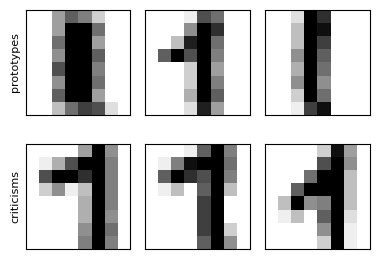

digit 7: 125 images, prototypes [15, 80, 56], criticisms [53, 21, 35]


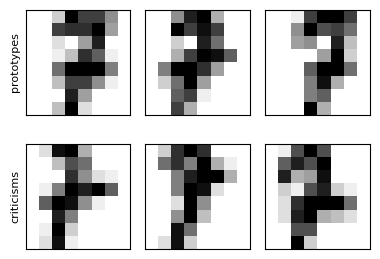

In [2]:
def rbf(A, B, g):
    d = ((A[:, None, :] - B[None, :, :]) ** 2).sum(-1)
    return np.exp(-g * d)

def mmd_critic(Xc, m=3, c=3, g=0.05):
    K = rbf(Xc, Xc, g)
    colmean = K.mean(0)
    P = []
    for _ in range(m):                         # greedy: add the point that lowers MMD most
        best, bv = None, -np.inf
        for j in range(len(Xc)):
            if j in P:
                continue
            S = P + [j]
            v = 2 * colmean[S].sum() / len(S) - K[np.ix_(S, S)].sum() / len(S) ** 2
            if v > bv:
                best, bv = j, v
        P.append(best)
    witness = colmean - K[:, P].mean(1)
    C = [j for j in np.argsort(-witness) if j not in P][:c]
    return P, C, witness

def show(rows, titles):
    fig, axes = plt.subplots(len(rows), len(rows[0]), figsize=(1.3 * len(rows[0]), 1.5 * len(rows)))
    for r, row in enumerate(rows):
        for c, img in enumerate(row):
            ax = axes[r, c]; ax.imshow(img.reshape(8, 8), cmap="gray_r"); ax.set_xticks([]); ax.set_yticks([])
            if c == 0: ax.set_ylabel(titles[r], fontsize=8)
    plt.tight_layout(); plt.show()

for digit in (1, 7):
    Xc = Xtr[ytr == digit]
    P, C, w = mmd_critic(Xc)
    print(f"digit {digit}: {len(Xc)} images, prototypes {P}, criticisms {[int(c) for c in C]}")
    show([[Xc[i] for i in P], [Xc[i] for i in C]], ["prototypes", "criticisms"])

**Checkpoint 2:** 127 training images of the digit 1 and 125 of the digit 7. The prototypes look like ordinary handwritten ones and sevens; the criticisms look unusual (a one with a base and a flag, a seven with a crossbar or an odd slant). Write down in one sentence what each criticism tells you that the prototypes hide.

## Part B. Neighbors in pixel space or in the model's representation?

We train a small neural network and then explain each test prediction by its five nearest training images. We can measure nearness in raw pixels or in the network's hidden layer. Which neighbors agree more often with what the *model* predicted, especially when the model is wrong?

In [3]:
net = MLPClassifier(hidden_layer_sizes=(32,), max_iter=600, random_state=0).fit(Xtr, ytr)
pred = net.predict(Xte)
wrong = np.where(pred != yte)[0]
print("test accuracy:", round(net.score(Xte, yte), 3), " wrong predictions:", len(wrong))
hidden = lambda Z: np.maximum(0, Z @ net.coefs_[0] + net.intercepts_[0])   # the 32 hidden units

def neighbors(A, B, k=5):
    d = ((B[:, None, :] - A[None, :, :]) ** 2).sum(-1)
    return np.argsort(d, 1)[:, :k]

for name, A, B in (("pixel space", Xtr, Xte), ("hidden layer", hidden(Xtr), hidden(Xte))):
    nb = neighbors(A, B)
    vote = np.array([np.bincount(ytr[r], minlength=10).argmax() for r in nb])
    print(f"{name:12s}: neighbor vote agrees with the model on {np.mean(vote == pred):.3f} of all test images "
          f"and on {np.mean(vote[wrong] == pred[wrong]):.3f} of the wrong ones")

test accuracy: 0.978  wrong predictions: 12
pixel space : neighbor vote agrees with the model on 0.976 of all test images and on 0.417 of the wrong ones
hidden layer: neighbor vote agrees with the model on 0.985 of all test images and on 0.667 of the wrong ones


**Checkpoint 3:** test accuracy 0.978 with 12 wrong predictions. Pixel-space neighbors agree with the model on 0.976 of all images but on only 0.417 of the wrong ones (5 of 12); hidden-layer neighbors agree on 0.985 and 0.667 (8 of 12). Small differences across scikit-learn versions are possible; the ordering should hold.

test image 32: true 7, model says 9; pixel neighbors [7, 7, 7, 7, 7], hidden neighbors [9, 7, 7, 7, 7]


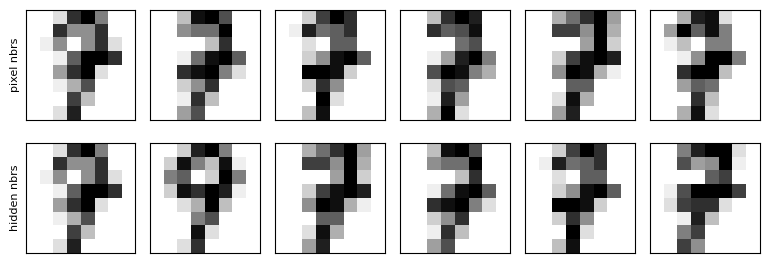

test image 85: true 8, model says 1; pixel neighbors [8, 8, 8, 1, 1], hidden neighbors [1, 1, 1, 1, 1]


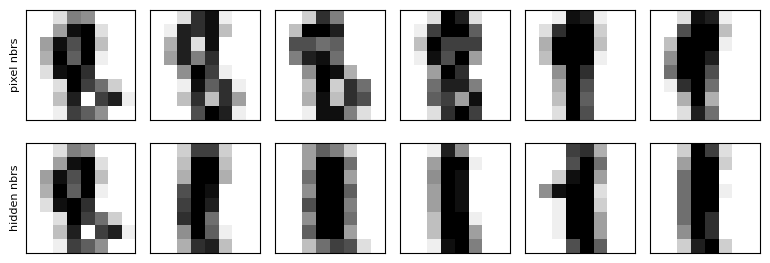

test image 100: true 1, model says 8; pixel neighbors [1, 1, 5, 1, 1], hidden neighbors [8, 1, 8, 8, 5]


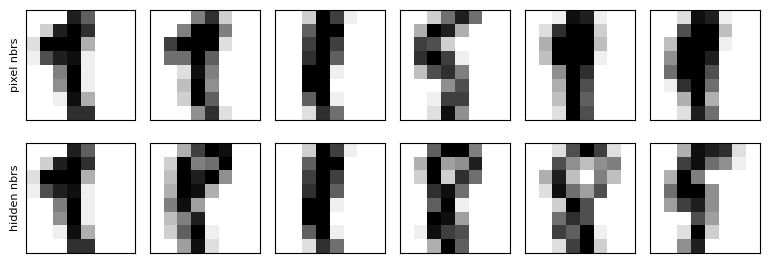

test image 114: true 2, model says 1; pixel neighbors [2, 2, 1, 1, 1], hidden neighbors [2, 2, 1, 1, 1]


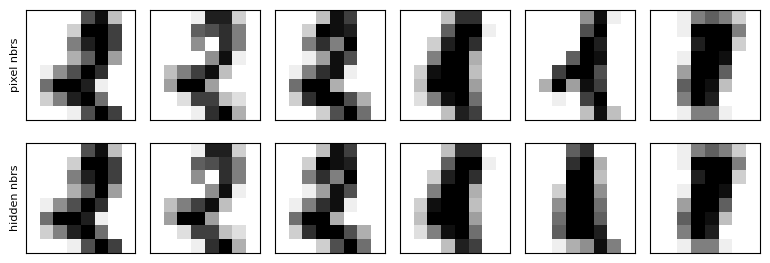

In [4]:
nbp, nbh = neighbors(Xtr, Xte), neighbors(hidden(Xtr), hidden(Xte))
for i in wrong[:4]:
    print(f"test image {i}: true {yte[i]}, model says {pred[i]}; "
          f"pixel neighbors {ytr[nbp[i]].tolist()}, hidden neighbors {ytr[nbh[i]].tolist()}")
    show([[Xte[i]] + [Xtr[j] for j in nbp[i]], [Xte[i]] + [Xtr[j] for j in nbh[i]]], ["pixel nbrs", "hidden nbrs"])

**Checkpoint 4:** for each wrong prediction you see the test image (first column) and its five neighbors in each space. Look for cases where the hidden-layer neighbors carry the model's wrong label: they show what the model has grouped the image with.

## Questions

1. Which kind of neighbor is the better explanation of *the model*, and which is the better explanation of *the data*? Use the Checkpoint 3 numbers.
2. Would you show the criticisms to a data labeling team, to a customer, or to neither? Why?
3. A neighbor explanation shows real training images. Name one kind of data where that would be unacceptable, and one change that would make it acceptable.